# Figure 1

Assembles Figure 1 from the benchmark results, using the same plotting functions as the benchmark notebooks (`../benchmarks/fig_panels.py`) and the shared style (`../benchmarks/pub_style.py`).

| Panel | Content | Data (written by) |
|---|---|---|
| a | Model architecture (full width) | `assets/architecture.png` (drawn separately; a placeholder is shown until the file exists) |
| b | 3Di identity, ESM3Di vs ProstT5, with the random-baseline median | `../benchmarks/quality/results/3di_benchmark.csv` (`../benchmarks/quality/3di_alignment.ipynb`) |
| c | SCOPe family-level sensitivity | `../benchmarks/quality/results/scope_sensitivity.csv` (`../benchmarks/quality/scope_family.ipynb`) |
| d | Runtime vs number of sequences: all methods end to end (CLI), and ESM3Di also inference only. Inference-only timings exist only for ESM3Di: ProstT5 and ColabFold were timed as CLI calls | `../benchmarks/speed/results/final2_nseq.csv`, `final2_nseq_esm3di_cli.csv` (`../benchmarks/speed/plot_results.ipynb`) |

Output: `figures/figure1.pdf` (vector) and `.png` (600 dpi), 183 mm wide.

In [1]:
# Re-import fig_panels/pub_style when they change, without restarting the kernel
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch

sys.path.insert(0, "../benchmarks")  # holds the shared figure style and plotting functions
from pub_style import (
    MM, MUTED_TEXT, WIDTH_DOUBLE, add_aligned_panel_labels, save_pub, use_pub_style,
)
from fig_panels import (
    IDENTITY_ARGS, plot_method_scatter, plot_runtime_end_to_end_and_inference, plot_scope_level,
)

use_pub_style()
OUT_DIR = Path("figures")
ARCHITECTURE_IMAGE = Path("assets/architecture.png")

# Layout in mm. The figure height follows from these and the architecture image's aspect ratio.
FIG_WIDTH = WIDTH_DOUBLE / MM
LETTER_GUTTER = 4  # left of panel a, so the letter does not touch the image
PLACEHOLDER_HEIGHT = 50  # height of panel a until the image exists
ROW_GAP = 5  # between panel a and the top of panels b-d
AXES_LEFT = 11  # room for the tick and axis labels of panel b
AXES_GAP = 13.5  # between panels b, c and d, holding the tick and axis labels of the next panel
AXES_BOTTOM = 10
RIGHT_MARGIN = 0.5

identity_df = pd.read_csv("../benchmarks/quality/results/3di_benchmark.csv")
scope_df = pd.read_csv("../benchmarks/quality/results/scope_sensitivity.csv")
nseq_df = pd.read_csv("../benchmarks/speed/results/final2_nseq.csv")
esm3di_cli_df = pd.read_csv("../benchmarks/speed/results/final2_nseq_esm3di_cli.csv")

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


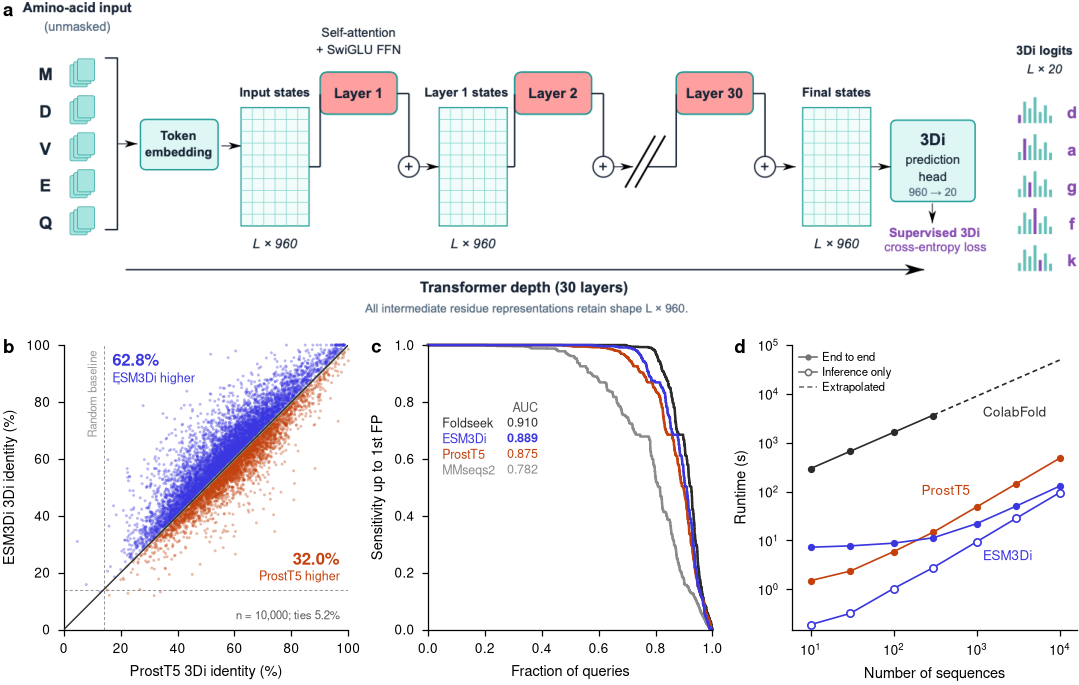

In [2]:
def load_architecture():
    """The architecture image cropped to its content, or None if it does not exist yet."""
    if not ARCHITECTURE_IMAGE.exists():
        return None
    image = plt.imread(ARCHITECTURE_IMAGE)
    ink = (image[..., :3] < 0.95).any(axis=-1)
    rows, columns = np.flatnonzero(ink.any(axis=1)), np.flatnonzero(ink.any(axis=0))
    return image[rows[0]:rows[-1] + 1, columns[0]:columns[-1] + 1]


def draw_architecture(ax, image):
    """Panel a: the architecture image if it exists, otherwise a placeholder of the same area."""
    ax.set_axis_off()
    if image is not None:
        ax.imshow(image)
        return
    ax.add_patch(FancyBboxPatch((0.02, 0.04), 0.96, 0.92, boxstyle="round,pad=0,rounding_size=0.02",
                                transform=ax.transAxes, fill=False, ec="0.75", lw=0.6, ls=(0, (4, 3))))
    ax.text(0.5, 0.5, "Model architecture", transform=ax.transAxes, ha="center", va="center",
            color=MUTED_TEXT)


architecture = load_architecture()
a_width = FIG_WIDTH - LETTER_GUTTER - RIGHT_MARGIN
a_height = (PLACEHOLDER_HEIGHT if architecture is None
            else a_width * architecture.shape[0] / architecture.shape[1])
axes_size = (FIG_WIDTH - AXES_LEFT - RIGHT_MARGIN - 2 * AXES_GAP) / 3  # panels b-d are square
fig_height = a_height + ROW_GAP + axes_size + AXES_BOTTOM

fig = plt.figure(figsize=(WIDTH_DOUBLE, fig_height * MM))


def place(ax, left, bottom, width, height):
    """Position an axes in mm from the bottom-left corner of the figure."""
    ax.set_position([left / FIG_WIDTH, bottom / fig_height, width / FIG_WIDTH, height / fig_height])


# Top row: architecture over the full width; bottom row: the three result panels. The grid tells
# add_aligned_panel_labels the rows and columns; the positions themselves are set in mm, so that
# panel a has exactly the shape of its image and leaves no blank margins.
grid = fig.add_gridspec(2, 3)
panels = {
    "a": fig.add_subplot(grid[0, :]),
    "b": fig.add_subplot(grid[1, 0]),
    "c": fig.add_subplot(grid[1, 1]),
    "d": fig.add_subplot(grid[1, 2]),
}
place(panels["a"], LETTER_GUTTER, fig_height - a_height, a_width, a_height)
for column, letter in enumerate("bcd"):
    place(panels[letter], AXES_LEFT + column * (axes_size + AXES_GAP), AXES_BOTTOM, axes_size, axes_size)

draw_architecture(panels["a"], architecture)
plot_method_scatter(panels["b"], identity_df, **IDENTITY_ARGS,
                    baseline=identity_df["baseline_identity"].median())
plot_scope_level(panels["c"], scope_df, "Family", show_title=False)
plot_runtime_end_to_end_and_inference(panels["d"], nseq_df, esm3di_cli_df)
add_aligned_panel_labels(fig, panels)

save_pub(fig, "figure1", OUT_DIR)
plt.show()